<a href="https://colab.research.google.com/github/LokeshIITM/22f3000227/blob/main/Week_7_vrs_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week-7

Decision trees and KNN

In [18]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams['font.size'] = 15

## Decision Trees

**Decision stumps**

A decision stump is a decision tree that has a single question at the root node which splits into two leaf nodes. A decision stump partitions the dataset based on a single question: $f_k < \theta$. This is therefore the simplest decision tree that we can come up with.

---
Use the following decision stump for problems 1 and 3: The root has $1000$ data-points out of which $200$ belong to class-1. The left child-node has $100$ data-points out of which $50$ belong to class-1.

### Problem-1

Write a function `entropy` that accepts the proportion of points that belong to class-1 in a node as argument and returns the entropy. Use $\log_2$ for all computations.

Use this function to compute the entropy of the parent node.

In [19]:
### Solution ###
def entropy(p):
    p = np.asarray(p, dtype=float)
    out = np.zeros_like(p)
    mask = (p > 0) & (p < 1)
    pm = p[mask]
    out[mask] = -pm*np.log2(pm) - (1-pm)*np.log2(1-pm)
    return out if out.shape else float(out)

# parent node: 200 of 1000 belong to class-1
E_parent = entropy(np.array(200/1000))
print(E_parent)

0.7219280948873623


### Problem-2

Plot the entropy of a node as a function of $p$, the proportion of data-points that belong to class $+1$.

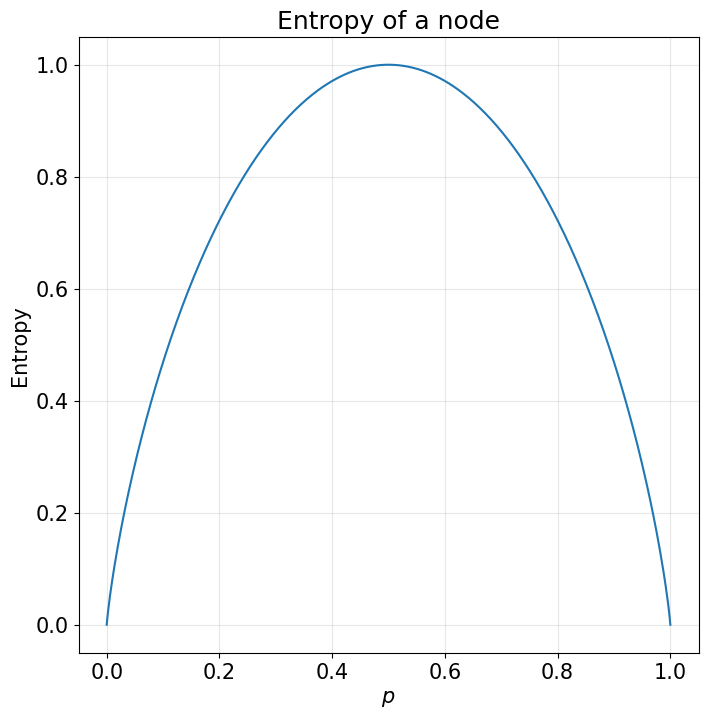

In [20]:
### Solution ###
p = np.linspace(0, 1, 500)
plt.plot(p, entropy(p))
plt.xlabel('$p$'); plt.ylabel('Entropy')
plt.title('Entropy of a node')
plt.grid(alpha=0.3)
plt.show()

Entropy is maximum at p = 0.5, where it equals 1.000. It's 0 at p = 0 and p = 1, and symmetric about 0.5.

### Problem-3

Write a function `IG` that accepts the following arguments:

- `E`: entropy of the parent node `Q`
- `El`: entropy of the left child `L`
- `Er`: entropy of the right child `R`
- `gamma`: proportion of data-points in left child

Use this function to compute the information gain for the parent node.

In [21]:
### Solution ###
def IG(E, El, Er, gamma):
    return E - (gamma*El + (1-gamma)*Er)

# left child: 50 of 100 -> p = 0.5 ;  right child: 150 of 900 -> p = 1/6
gamma = 100/1000
El = entropy(np.array(0.5))
Er = entropy(np.array(150/900))
print(IG(E_parent, El, Er, gamma))

0.03690791540384364


### Problem-4

Consider a decision stump with $1000$ data-points. Call the root node $Q$ and the left and right leaf nodes $L$ and $R$.

- The proportion of data-points that belong to class $+1$ in $Q$ is equal to $0.4$
- The proportion of points in the left node is equal to $0.7$, that is, $\gamma = 0.7$
-  $q$ is the proportion of data-points that belong to class $+1$ in $L$

What are the minimum ($q_{\min}$) and maximum ($q_{\max}$) values of $q$?

In [22]:
### Solution ###
# Q: 1000 points, 400 belong to +1.  L has 700 points, R has 300.
# #(+1 in L) <= min(400, 700) = 400            -> q_max = 400/700
# #(+1 in L) >= 400 - 300 = 100 (R holds <=300) -> q_min = 100/700
q_min, q_max = 100/700, 400/700
print(q_min, q_max)

0.14285714285714285 0.5714285714285714


### Problem-5

Using the above information, plot the information gain of the root as a function of $q$, where $q \in [q_{\min}, q_{\max}]$. Record at least two interesting observations.

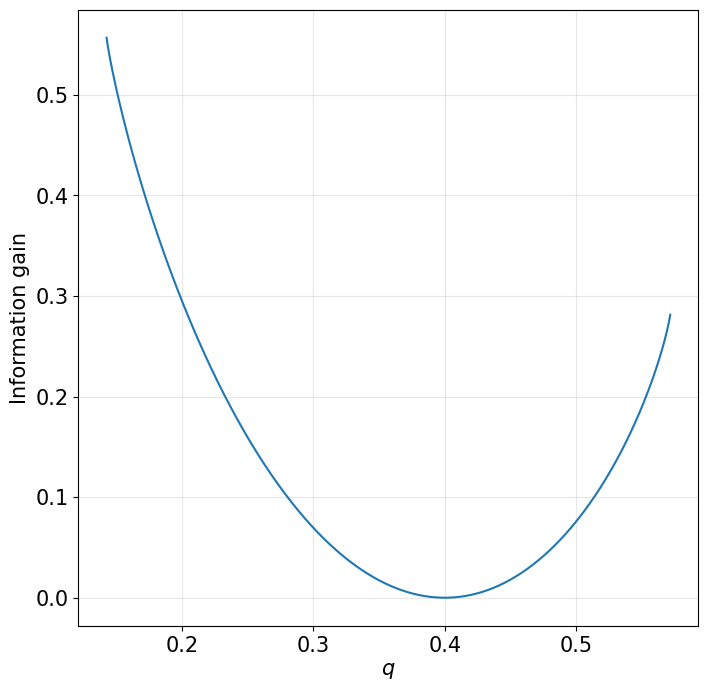

q at max IG: 0.14285714285714285 max IG: 0.5567796494470395
IG at q = 0.4: 0.0


In [23]:
### Solution ###
q = np.linspace(q_min, q_max, 500)
g = 0.7
r = (0.4 - g*q) / (1 - g)          # proportion of +1 in right node
ig = IG(entropy(np.array(0.4)), entropy(q), entropy(r), g)

plt.plot(q, ig)
plt.xlabel('$q$'); plt.ylabel('Information gain')
plt.grid(alpha=0.3)
plt.show()
print('q at max IG:', q[np.argmax(ig)], 'max IG:', ig.max())
print('IG at q = 0.4:', IG(entropy(np.array(0.4)), entropy(np.array(0.4)),
                           entropy(np.array(0.4)), g))

q where IG = 0 is 0.400. Max IG is 0.557, attained at q = 0.143 (= q_min). IG at q_max = 4/7 is 0.281.

### Problem-6

We will work with the dataset `X` for the next five problems. Visualize the data using a scatter plot. Color the points that belong to class $+1$ using "green" and those that belong to class $0$ using "red".

In [24]:
### Data ###
### DO NOT CHANGE THE CONTENTS OF THIS CELL ###
rng = np.random.default_rng(seed = 1001)
n_per = 50
cov = np.eye(2) / 10
X1 = rng.multivariate_normal([1, 1], cov, n_per)
y1 = np.ones(n_per)
X2 = rng.multivariate_normal([5, 3], cov , n_per)
y2 = np.zeros(n_per)
X3 = rng.multivariate_normal([3, 4], cov, n_per)
y3 = np.ones(n_per)
X4 = rng.multivariate_normal([3, 2], cov, n_per)
y4 = np.zeros(n_per)
X = np.concatenate((X1, X2, X3, X4), axis = 0)
y = np.int64(np.concatenate((y1, y2, y3, y4)))
### DO NOT CHANGE THE CONTENTS OF THIS CELL ###

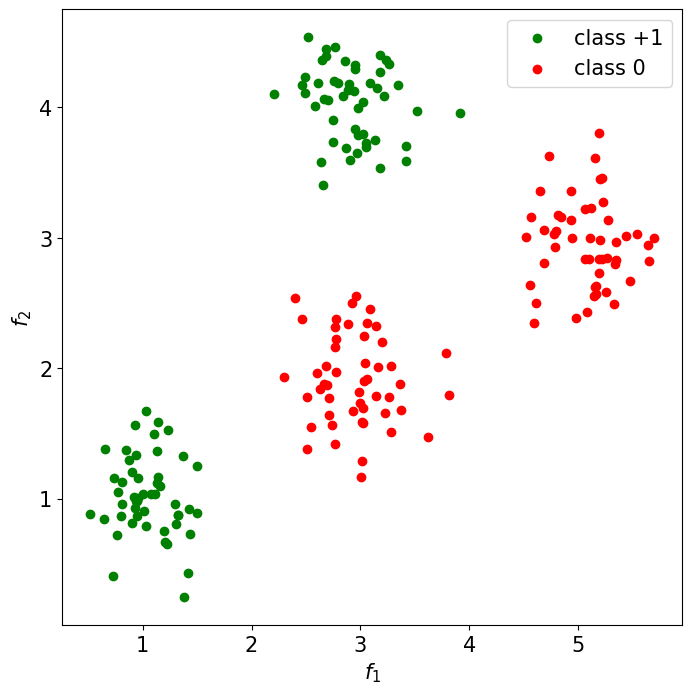

In [25]:
### Solution ###
plt.scatter(X[y==1, 0], X[y==1, 1], color='green', label='class +1')
plt.scatter(X[y==0, 0], X[y==0, 1], color='red', label='class 0')
plt.xlabel('$f_1$'); plt.ylabel('$f_2$'); plt.legend(); plt.show()

4 clusters, 2 per class; not linearly separable; 100 points per class, 200 total.

### Problem-7

If you were to use a decision stump as a classifier:

- What is the best question $f_k < \theta$?
    - enter the feature index, $k$ (use zero-indexing)
    - enter the value of $\theta$
- What is the information gain for this question?

---

Write the function named `best_split` to solve this problem:

The function should accept the feature matrix `X` and the label vector `y` as arguements. It should return the tuple `(feat_best, value_best, ig_best)`.

In [26]:
### Solution ###
def node_entropy(y):
    if len(y) == 0:
        return 0.0
    return float(entropy(np.array(y.mean())))

def best_split(X, y):
    E = node_entropy(y)
    feat_best, value_best, ig_best = None, None, -np.inf
    for k in range(X.shape[1]):
        vals = np.unique(X[:, k])
        thetas = (vals[:-1] + vals[1:]) / 2
        for theta in thetas:
            mask = X[:, k] < theta
            gamma = mask.mean()
            if gamma == 0 or gamma == 1:
                continue
            ig = IG(E, node_entropy(y[mask]), node_entropy(y[~mask]), gamma)
            if ig > ig_best:
                feat_best, value_best, ig_best = k, theta, ig
    return feat_best, value_best, ig_best

print(best_split(X, y))

(0, np.float64(2.2534643163631065), np.float64(0.31925145895127793))


### Problem-8

Grow a decision tree for this problem. You may have to use two programming concepts:

- recursion
- binary trees

Once you have grown the tree, answer the following questions:

- How many internal nodes does your tree have?
- How many leaf nodes does it have?

In [27]:
### Solution ###
class Node:
    def __init__(self):
        self.feat = self.value = self.left = self.right = self.label = None
    def is_leaf(self):
        return self.label is not None

def grow(X, y):
    node = Node()
    if len(np.unique(y)) == 1 or len(y) == 0:
        node.label = int(y[0]) if len(y) else 0
        return node
    feat, value, ig = best_split(X, y)
    if feat is None or ig <= 1e-12:
        node.label = int(np.round(y.mean()))
        return node
    node.feat, node.value = feat, value
    mask = X[:, feat] < value
    node.left = grow(X[mask], y[mask])
    node.right = grow(X[~mask], y[~mask])
    return node

tree = grow(X, y)

def count(node):
    if node.is_leaf():
        return 0, 1
    il, ll = count(node.left)
    ir, lr = count(node.right)
    return il + ir + 1, ll + lr

print('internal nodes, leaf nodes:', count(tree))

internal nodes, leaf nodes: (3, 4)


### Problem-9

Predict the label of the point $(3, 4)$.

In [28]:
### Solution ###
def predict_tree(node, x):
    while not node.is_leaf():
        node = node.left if x[node.feat] < node.value else node.right
    return node.label

print(predict_tree(tree, np.array([3, 4])))

1


### Problem-10

Plot the decision boundary.

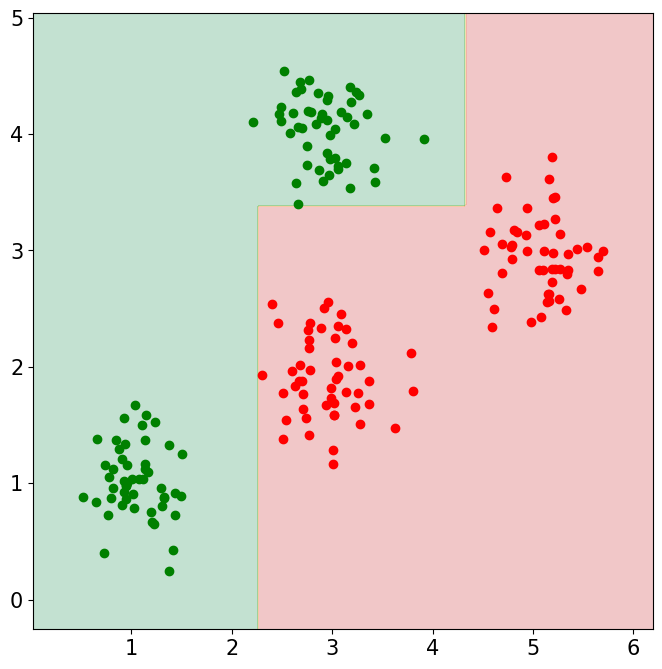

In [29]:
### Solution ###
x1 = np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 300)
x2 = np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 300)
XX, YY = np.meshgrid(x1, x2)
grid = np.c_[XX.ravel(), YY.ravel()]
Z = np.array([predict_tree(tree, p) for p in grid]).reshape(XX.shape)

plt.contourf(XX, YY, Z, alpha=0.25, cmap='RdYlGn')
plt.scatter(X[y==1, 0], X[y==1, 1], color='green')
plt.scatter(X[y==0, 0], X[y==0, 1], color='red')
plt.show()

Axis-parallel rectangles, 4 regions (matching the 4 leaves), 3 splits.

## KNN


In [30]:
### Data ###
### DO NOT EDIT THIS CELL ###
rng = np.random.default_rng(seed = 1001)
X = rng.uniform(-10, 10, (100, 2))
y = np.int32(np.zeros(X.shape[0]))
y[X[:, 1] > X[:, 0]] = 1
X = np.concatenate((X,
                   rng.multivariate_normal([-5, 5], np.eye(2), 10)),
                   axis = 0)
y = np.concatenate((y, np.int32(np.zeros(10))))
### DO NOT EDIT THIS CELL ###

### Problem-11

Visualize the data using a scatter plot. Use red for class $0$ and green for class $1$.

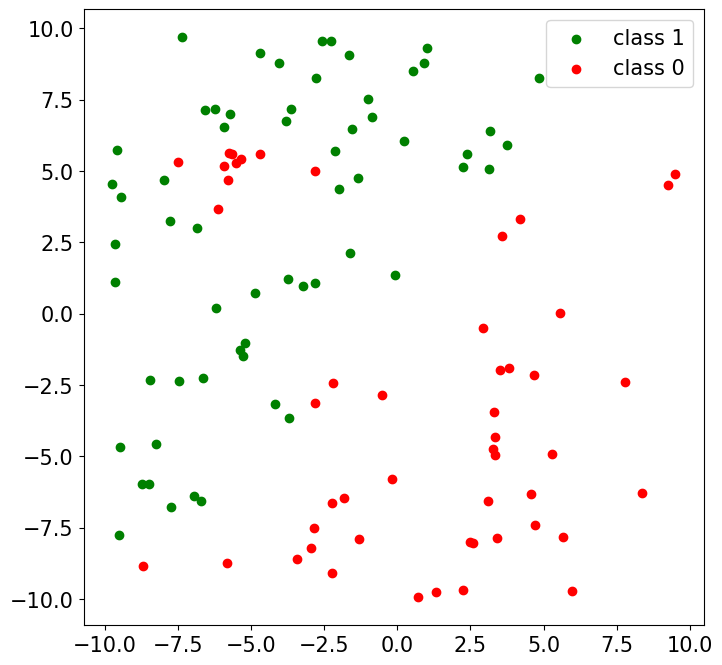

In [31]:
### Solution ###
plt.scatter(X[y==1, 0], X[y==1, 1], color='green', label='class 1')
plt.scatter(X[y==0, 0], X[y==0, 1], color='red', label='class 0')
plt.legend(); plt.show()

True boundary is the line x₂ = x₁; 110 points total, 10 of them mislabeled noise near (−5, 5).

### Problem-12

Write a function `predict` that accepts the following arguments:

- `X` - feature matrix
- `y` - label vector
- `x_test` - test data-point
- `k` - number of neighbors

The function should return the prediction for the point `x_test`. Use this function to compute the predicted label for the point $(-3, -2)$ with $k = 10$.

In [32]:
### Solution ###
def predict(X, y, x_test, k):
    d = np.linalg.norm(X - x_test, axis=1)
    idx = np.argsort(d)[:k]
    return int(np.bincount(y[idx]).argmax())

print(predict(X, y, np.array([-3, -2]), 10))

1


### Problem-13

Plot the decision boundary for different values of $k$:

- $k = 1$
- $k = 3$
- $k = 7$
- $k = 15$
- $k = 31$
- $k = 63$

Record at least two observations.

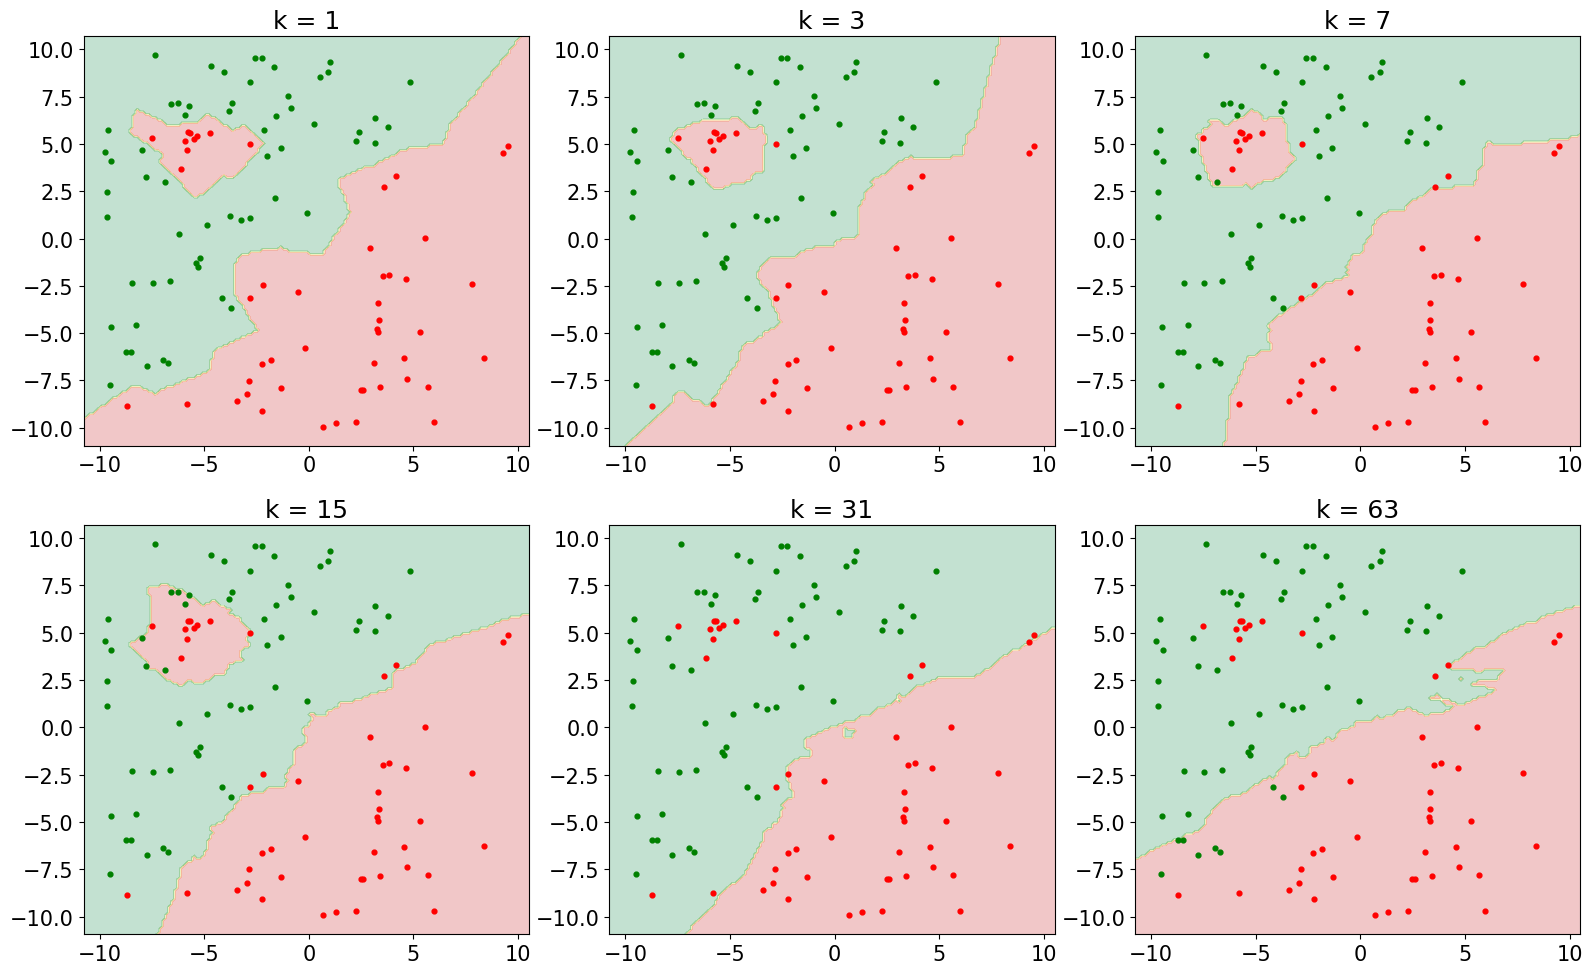

In [33]:
### Solution ###
ks = [1, 3, 7, 15, 31, 63]
x1 = np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 150)
x2 = np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 150)
XX, YY = np.meshgrid(x1, x2)
grid = np.c_[XX.ravel(), YY.ravel()]

fig, axs = plt.subplots(2, 3, figsize=(16, 10))
for ax, k in zip(axs.ravel(), ks):
    Z = np.array([predict(X, y, p, k) for p in grid]).reshape(XX.shape)
    ax.contourf(XX, YY, Z, alpha=0.25, cmap='RdYlGn')
    ax.scatter(X[y==1, 0], X[y==1, 1], color='green', s=12)
    ax.scatter(X[y==0, 0], X[y==0, 1], color='red', s=12)
    ax.set_title(f'k = {k}')
plt.tight_layout(); plt.show()

k = 1 overfits the noise cluster; large k over-smooths; the noise island disappears somewhere around k = 15–31.